In [1]:
# Visualization parameters
from pathlib import Path
import importlib
import sys

PACKAGE_ROOT = next((path for path in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (path / "interactions").is_dir()), None)
if PACKAGE_ROOT is None:
    raise FileNotFoundError("Run this notebook from inside AIJ_fig_submit.")
FIGURE_DIR = PACKAGE_ROOT / "Fig_03_distributions"
SCRIPT_DIR = FIGURE_DIR / "source"
sys.path.insert(0, str(SCRIPT_DIR))
import render_with_llm_cache as renderer

renderer = importlib.reload(renderer)

OUTPUT_DIR = FIGURE_DIR / "outputs"
SMALL_DATA_ROOT = str(PACKAGE_ROOT / "interactions" / "generalization")
LLM_SINGLE_CACHE_ROOT = PACKAGE_ROOT / "interactions" / "robustness_n" / "llm_target_single_cache_globalq" / "n=10"
LLM_TASK = "finance"
MASKS_PATH = PACKAGE_ROOT / "interactions" / "llm" / "masks.npy"

# Same k values as the original Fig.3: first 1, first 3, and all 5 baseline models.
K_VALUES = [1, 3, 5]
ALPHA_LIST = [0.7, 0.85, 1.0]
Y_SCALER = 2
NON_GEN_YLIM_SCALE = 4.0

FONT_SIZE = 8
BAR_WIDTH = 0.72

# Panel and figure layout, matching main.ipynb.
SUBPLOT_WIDTH = 1.5
SUBPLOT_HEIGHT = 1.0
WSPACE_INCHES = 0.12
HSPACE_INCHES = 0.24
GROUP_GAP_INCHES = 0.5
LEFT_MARGIN = 0.15
RIGHT_MARGIN = 0.02
TOP_MARGIN = 0.02
BOTTOM_MARGIN = 0.20
N_COLS = 7

ORIG_COLORS = {
    "all_pos": "#CE593B",
    "all_neg": "#F6CDBF",
    "gen_pos": "#4B73C3",
    "gen_neg": "#A9C0EE",
}

# Apply notebook parameters to the reusable renderer.
renderer.OUTPUT_DIR = OUTPUT_DIR
renderer.SMALL_DATA_ROOT = SMALL_DATA_ROOT
renderer.LLM_SINGLE_CACHE_ROOT = LLM_SINGLE_CACHE_ROOT
renderer.LLM_TASK = LLM_TASK
renderer.MASKS_PATH = MASKS_PATH
renderer.K_VALUES = K_VALUES
renderer.ALPHA_LIST = ALPHA_LIST
renderer.Y_SCALER = Y_SCALER
renderer.NON_GEN_YLIM_SCALE = NON_GEN_YLIM_SCALE
renderer.FONT_SIZE = FONT_SIZE
renderer.BAR_WIDTH = BAR_WIDTH
renderer.SUBPLOT_WIDTH = SUBPLOT_WIDTH
renderer.SUBPLOT_HEIGHT = SUBPLOT_HEIGHT
renderer.WSPACE_INCHES = WSPACE_INCHES
renderer.HSPACE_INCHES = HSPACE_INCHES
renderer.GROUP_GAP_INCHES = GROUP_GAP_INCHES
renderer.LEFT_MARGIN = LEFT_MARGIN
renderer.RIGHT_MARGIN = RIGHT_MARGIN
renderer.TOP_MARGIN = TOP_MARGIN
renderer.BOTTOM_MARGIN = BOTTOM_MARGIN
renderer.N_COLS = N_COLS
renderer.ORIG_COLORS = ORIG_COLORS

# Keep all tau values explicit in the notebook.
SMALL_TAU = {
    "ResNet-20 on MNIST": 0.01,
    "ResNet-20 on CIFAR-10": 0.03,
    "VGG-11 on CIFAR-10": 0.03,
    "BERT-Medium on SST-2": 0.01,
    "BERT-Base on SST-2": 0.01,
}
LLM_TAU = {
    "Qwen2.5-7B on Finance": 0.03,
    "Llama-3-8B on Finance": 0.03,
    "GLM-Z1-9B on Finance": 0.03,
    "Phi-4 on Finance": 0.03,
}

for config in renderer.SMALL_MODELS:
    config["tau"] = SMALL_TAU[config["label"]]
for config in renderer.LLM_MODELS:
    config["tau"] = LLM_TAU[config["label"]]

EXPECTED_LLM_SAMPLE_COUNT = 20
LLM_SAMPLE_NAMES = {}
for config in renderer.LLM_MODELS:
    sample_names = renderer.llm_common_sample_names(config["target"], config["baselines"])
    if len(sample_names) != EXPECTED_LLM_SAMPLE_COUNT:
        raise RuntimeError(
            f'{config["label"]} uses {len(sample_names)} LLM samples, '
            f'expected {EXPECTED_LLM_SAMPLE_COUNT}: {sample_names}'
        )
    LLM_SAMPLE_NAMES[config["label"]] = sample_names

N_ROWS = len(renderer.SMALL_MODELS) + len(renderer.LLM_MODELS)
FIGWIDTH = LEFT_MARGIN + N_COLS * SUBPLOT_WIDTH + (N_COLS - 1 - 2) * WSPACE_INCHES + 2 * GROUP_GAP_INCHES + RIGHT_MARGIN
FIGHEIGHT = TOP_MARGIN + N_ROWS * SUBPLOT_HEIGHT + (N_ROWS - 1) * HSPACE_INCHES + BOTTOM_MARGIN
FIGSIZE = (FIGWIDTH, FIGHEIGHT)

print("rows:", N_ROWS, "cols:", N_COLS, "figsize:", FIGSIZE)
print("small tau:", [config["tau"] for config in renderer.SMALL_MODELS])
print("LLM tau:", [config["tau"] for config in renderer.LLM_MODELS])
print("LLM sample counts:", {label: len(names) for label, names in LLM_SAMPLE_NAMES.items()})


rows: 9 cols: 7 figsize: (12.15, 11.139999999999999)
small tau: [0.01, 0.03, 0.03, 0.01, 0.01]
LLM tau: [0.03, 0.03, 0.03, 0.03]
LLM sample counts: {'Qwen2.5-7B on Finance': 20, 'Llama-3-8B on Finance': 20, 'GLM-Z1-9B on Finance': 20, 'Phi-4 on Finance': 20}


[plot] ResNet-20 on MNIST


[plot] ResNet-20 on CIFAR-10


[plot] VGG-11 on CIFAR-10


[plot] BERT-Medium on SST-2


[plot] BERT-Base on SST-2


[plot] Qwen2.5-7B on Finance
[plot] Llama-3-8B on Finance


[plot] GLM-Z1-9B on Finance


[plot] Phi-4 on Finance


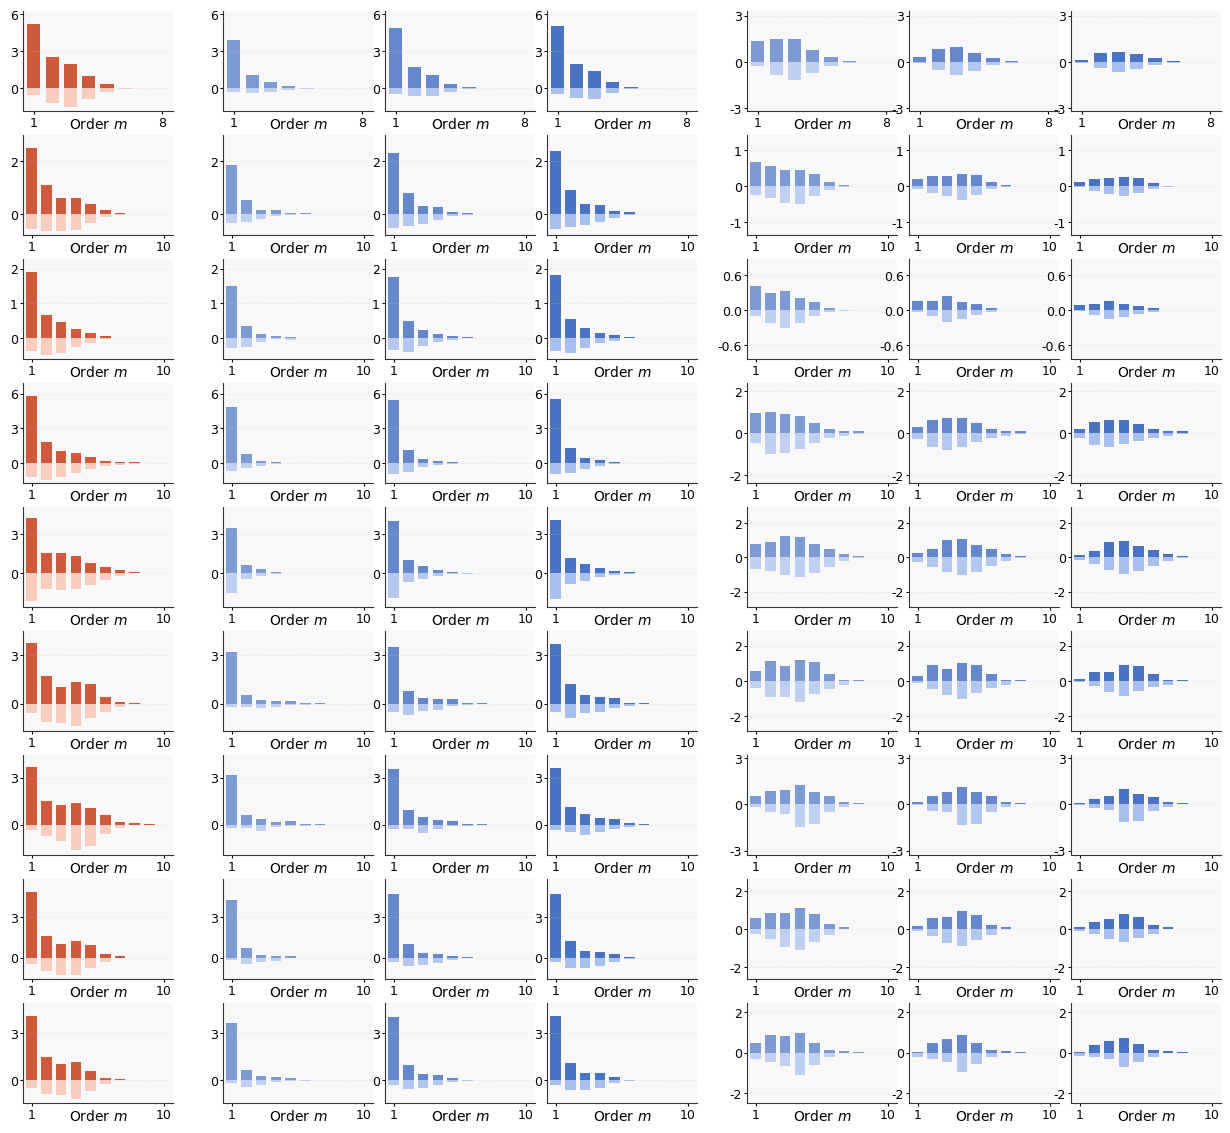

In [2]:
from pathlib import Path
import sys

sys.path.insert(0, str(PACKAGE_ROOT / "shared"))

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import MaxNLocator

from tool import apply_style, compute_generalization_orders, plot_signed_bars

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
apply_style(FONT_SIZE)

# Local style overrides to match the original reference figure.
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 9,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.edgecolor": "#333333",
    "xtick.major.size": 2.5,
    "ytick.major.size": 2.5,
    "ytick.major.width": 0.7,
    "grid.alpha": 0.3,
    "grid.linewidth": 0.5,
    "grid.color": "#CCCCCC",
    "figure.facecolor": "white",
    "axes.facecolor": "#F8F8F8",
})

fig = plt.figure(figsize=FIGSIZE)

# Compute exact column left positions in inches, with larger gaps between groups.
col_lefts = []
x = LEFT_MARGIN
for c in range(N_COLS):
    col_lefts.append(x)
    gap = GROUP_GAP_INCHES if c in (0, 3) else WSPACE_INCHES
    x += SUBPLOT_WIDTH + gap

# Compute exact row bottom positions in inches, from top to bottom.
row_bottoms = []
y = FIGHEIGHT - TOP_MARGIN - SUBPLOT_HEIGHT
for r in range(N_ROWS):
    row_bottoms.append(y)
    y -= SUBPLOT_HEIGHT + HSPACE_INCHES

axes = [[None] * N_COLS for _ in range(N_ROWS)]
for r in range(N_ROWS):
    for c in range(N_COLS):
        left = col_lefts[c] / FIGWIDTH
        bottom = row_bottoms[r] / FIGHEIGHT
        width = SUBPLOT_WIDTH / FIGWIDTH
        height = SUBPLOT_HEIGHT / FIGHEIGHT
        axes[r][c] = fig.add_axes([left, bottom, width, height])

MODELS = renderer.SMALL_MODELS + renderer.LLM_MODELS

for r, config in enumerate(MODELS):
    print(f"[plot] {config['label']}")
    if "target" in config:
        dists_by_k = renderer.compute_llm_generalization_orders(
            config["target"],
            config["baselines"],
            tau=config["tau"],
        )
    else:
        dists_by_k = {}
        for k in K_VALUES:
            baseline_seeds = list(range(k))
            dists_by_k[k] = compute_generalization_orders(
                target_root=config["target_root"],
                baseline_template=config["baseline_template"],
                baseline_seeds=baseline_seeds,
                prefix=config["prefix"],
                tau=config["tau"],
            )

    n_dim = len(dists_by_k[K_VALUES[0]]["all_pos"])
    all_pos_vals = []
    all_neg_vals = []
    non_gen_pos_vals = []
    non_gen_neg_vals = []
    for d in dists_by_k.values():
        all_pos_vals.extend([d["all_pos"].max(), d["gen_pos"].max(), d["non_gen_pos"].max()])
        all_neg_vals.extend([d["all_neg"].min(), d["gen_neg"].min(), d["non_gen_neg"].min()])
        non_gen_pos_vals.append(d["non_gen_pos"].max())
        non_gen_neg_vals.append(d["non_gen_neg"].min())
    y_pos_max = max(all_pos_vals) * 1.2 or 1.0
    y_neg_max = min(all_neg_vals) * 1.2 or -1.0
    non_gen_y_pos_max = max(non_gen_pos_vals) * 1.2 or 1.0
    non_gen_y_neg_max = min(non_gen_neg_vals) * 1.2 or -1.0

    def finalize_axis(ax, y_pos_max, y_neg_max, is_non_gen=False, non_gen_ylim_scale=1.0):
        ax.set_xticks([1, n_dim] if n_dim > 4 else np.arange(1, n_dim + 1))
        ax.tick_params(pad=1)
        ax.yaxis.set_major_locator(MaxNLocator(integer=True, nbins=3))
        for line in list(ax.lines):
            if np.allclose(line.get_ydata(), 0):
                line.remove()
        if is_non_gen:
            lower = (0.8 * y_neg_max - 0.2 * y_pos_max) / Y_SCALER
            upper = (-0.2 * y_neg_max + 0.8 * y_pos_max) / Y_SCALER
            center = (lower + upper) / 2
            half_range = (upper - lower) * non_gen_ylim_scale / 2
            ax.set_ylim(center - half_range, center + half_range)
        else:
            ax.set_ylim(y_neg_max, y_pos_max)

    # Column 0: all interactions.
    ax = axes[r][0]
    d = dists_by_k[K_VALUES[0]]
    plot_signed_bars(ax, d["all_pos"], d["all_neg"], ORIG_COLORS["all_pos"], ORIG_COLORS["all_neg"], width=BAR_WIDTH)
    finalize_axis(ax, y_pos_max, y_neg_max)
    ax.set_xlabel("Order $m$", fontsize=10)
    ax.xaxis.set_label_coords(0.5, -0.05)

    # Columns 1-3: generalizable interactions for k = 1, 3, 5.
    for c, k in enumerate(K_VALUES, start=1):
        ax = axes[r][c]
        d = dists_by_k[k]
        plot_signed_bars(ax, d["gen_pos"], d["gen_neg"], ORIG_COLORS["gen_pos"], ORIG_COLORS["gen_neg"], width=BAR_WIDTH)
        alpha = ALPHA_LIST[c - 1]
        for patch in ax.patches:
            patch.set_alpha(alpha)
        finalize_axis(ax, y_pos_max, y_neg_max)
        ax.set_xlabel("Order $m$", fontsize=10)
        ax.xaxis.set_label_coords(0.5, -0.05)

    # Columns 4-6: non-generalizable interactions for k = 1, 3, 5.
    for c, k in enumerate(K_VALUES, start=4):
        ax = axes[r][c]
        d = dists_by_k[k]
        plot_signed_bars(ax, d["non_gen_pos"], d["non_gen_neg"], ORIG_COLORS["gen_pos"], ORIG_COLORS["gen_neg"], width=BAR_WIDTH)
        alpha = ALPHA_LIST[c - 4]
        for patch in ax.patches:
            patch.set_alpha(alpha)
        finalize_axis(
            ax,
            non_gen_y_pos_max,
            non_gen_y_neg_max,
            is_non_gen=True,
            non_gen_ylim_scale=config.get("non_gen_ylim_scale", NON_GEN_YLIM_SCALE),
        )
        ax.set_xlabel("Order $m$", fontsize=10)
        ax.xaxis.set_label_coords(0.5, -0.05)

fig.savefig(OUTPUT_DIR / "main_with_llm_single_cache_from_notebook.pdf", bbox_inches=None, pad_inches=0.0)
fig.savefig(OUTPUT_DIR / "main_with_llm_single_cache_from_notebook.png", bbox_inches=None, pad_inches=0.0, dpi=300)
plt.show()
